In [1]:
import numpy as np
import uxarray as ux
import csv
from matplotlib import pyplot as plt
from matplotlib import colors
import matplotlib.animation as animation
import pygeode as pyg
from scipy.optimize import fsolve
import cartopy.crs as ccrs
from jfunctions import *

from functions_mpas_aqua import filter_data_for_ccews

from wavenumber_frequency_functions import *

from matplotlib.path import Path

from scipy import signal,fftpack, interpolate
from scipy.interpolate import griddata

%matplotlib widget

In [2]:
data_dir = '/data/phh1-hosted/cwp29/mpas-a/analysis/'
grid_path = '/store/ATMOS/cwp29/mpas-a/grids/x1.40962/x1.40962.grid.nc'

In [3]:
filtered_kelvin = filter_data_for_ccews(
    fname = data_dir+'precip_rate_n256.nc', 
    obsVar = 'precip_rate', 
    obsPerDay = 8,
    waveName = 'Kelvin',
    flipGrid = True,
    minLat = -10
)

filtered_wig = filter_data_for_ccews(
    fname = data_dir+'precip_rate_n256.nc', 
    obsVar = 'precip_rate', 
    obsPerDay = 8,
    waveName = 'WIG',
    flipGrid = True,
    minLat = -10
)

filtered_adv = filter_data_for_ccews(
    fname = data_dir+'precip_rate_n256.nc', 
    obsVar = 'precip_rate', 
    obsPerDay = 8,
    waveName = 'AD',
    flipGrid = True,
    minLat = -10
)

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering Kelvin

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering WIG

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering AD



In [4]:
print(filtered_kelvin.time)

<xarray.DataArray 'time' (time: 672)> Size: 5kB
array(['2000-05-01T03:00:00.000000000', '2000-05-01T06:00:00.000000000',
       '2000-05-01T09:00:00.000000000', ..., '2000-07-23T18:00:00.000000000',
       '2000-07-23T21:00:00.000000000', '2000-07-24T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 5kB 2000-05-01T03:00:00 ... 2000-07-24
Attributes:
    standard_name:  time
    long_name:      CF-compliant valid time
    axis:           T


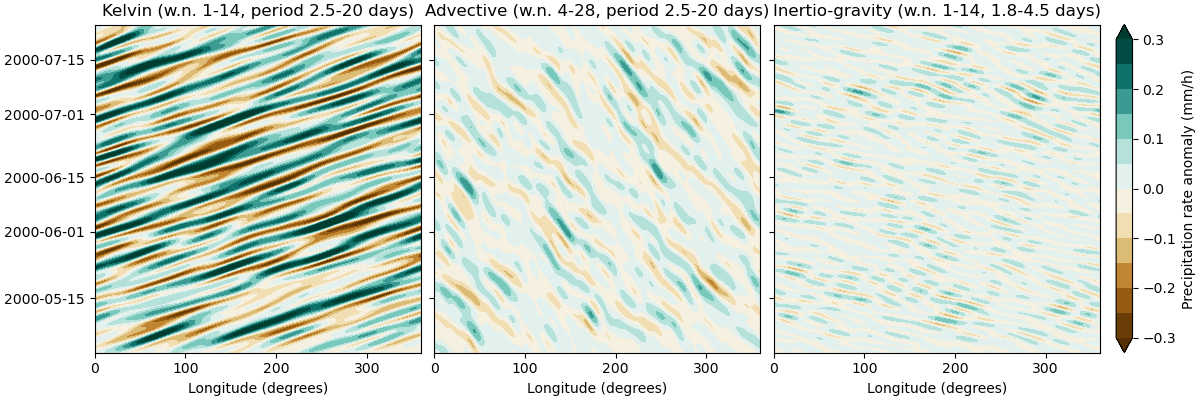

In [5]:
# Hovmoller diagram
time = filtered_kelvin.time
lons = pyg.regularlon(1024)

levels = np.linspace(-0.3, 0.3, 13)

fig, ax = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

kelvin_im = ax[0].contourf(lons, time, filtered_kelvin, levels=levels, cmap='BrBG', extend='both')
ax[0].set_title("Kelvin (w.n. 1-14, period 2.5-20 days)")
fig.colorbar(kelvin_im, ax=ax[-1], location='right', label="Precipitation rate anomaly (mm/h)")

adv_im = ax[1].contourf(lons, time, filtered_adv, levels=levels, cmap='BrBG', extend='both')
ax[1].set_title("Advective (w.n. 4-28, period 2.5-20 days)")

wig_im = ax[2].contourf(lons, time, filtered_wig, levels=levels, cmap='BrBG', extend='both')
ax[2].set_title("Inertio-gravity (w.n. 1-14, 1.8-4.5 days)")

for a in ax[1:]:
    a.set_yticklabels([])

for a in ax:
    a.set_xlabel("Longitude (degrees)")

save_fig(fig, '/home/cwp29/tmp/mpas/ccew.png', dpi=300)

In [6]:
waves = {
    'Kelvin': {
         'longname': 'Kelvin Waves',
         'wavenumber': np.array([1,14],dtype='f'),
         'period': np.array([2.5,20],dtype='f'),
         'depth': np.array([8,90],dtype='f')
        },
    'AD': {
         'longname': 'Advective Disturbances',
         'wavenumber': np.array([-28, -4],dtype='f'),
         'period': np.array([5.0,20],dtype='f'),
         'depth': np.array([2.5,12],dtype='f')
        },
    'MRG': {
         'longname': 'Mixed Rossby-Gravity Waves',
         'wavenumber': np.array([-10, -1],dtype='f'),
         'period': np.array([3, 10],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
    'WIG': {
         'longname': 'Westward Inertio-Gravity Waves',
         'wavenumber': np.array([-14, -1],dtype='f'),
         'period': np.array([1.8, 4.5],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
    'EIG': {
         'longname': 'Eastward Inertio-Gravity Waves',
         'wavenumber': np.array([1, 14],dtype='f'),
         'period': np.array([2, 4],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
}

In [7]:
#ds = xr.open_dataset(data_dir + 'precip_rate_n256.nc')
#ds = ds.reindex(lat=ds.lat[::-1])
#pr = ds.precip_rate

dsx = xr.open_dataset('/data/phh1-hosted/cwp29/mpas-a/u_nudge_test/latlon_diag.nc')

precip = dsx.rainc + dsx.i_rainc*100. + dsx.rainnc + dsx.i_rainnc*100.
pr = precip.differentiate("Time", datetime_unit="D")
pr = pr.rename({'latitude':'lat', 'longitude':'lon'})

print(pr)

raw_spectrum = spacetime_power(pr, lataggreg='mean', latitude_bounds=(-10, 10), dosymmetries=True, 
                               spd=8, segsize=int(96/8), noverlap=int(60/8))

sym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='symmetric'), freq_ax = 1)
asym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='antisymmetric'), freq_ax = 1)

sym_sig_spectrum = raw_spectrum.sel(component='symmetric')/sym_smooth_spectrum
asym_sig_spectrum = raw_spectrum.sel(component='antisymmetric')/asym_smooth_spectrum

wn = sym_sig_spectrum.wavenumber
f = sym_sig_spectrum.frequency

<xarray.DataArray (Time: 1224, lat: 180, lon: 360)> Size: 635MB
array([[[1.03538513e-01, 1.04377747e-01, 1.05228424e-01, ...,
         1.01093292e-01, 1.01898193e-01, 1.02714539e-01],
        [7.92808533e-02, 8.02497864e-02, 8.12034607e-02, ...,
         7.63015747e-02, 7.73048401e-02, 7.83004761e-02],
        [2.51426697e-02, 2.70576477e-02, 2.89726257e-02, ...,
         1.93138123e-02, 2.12707520e-02, 2.32048035e-02],
        ...,
        [1.05144501e-01, 1.03923798e-01, 1.02630615e-01, ...,
         1.08329773e-01, 1.07345581e-01, 1.06281281e-01],
        [2.47383118e-02, 2.37197876e-02, 2.26860046e-02, ...,
         2.76947021e-02, 2.67295837e-02, 2.57377625e-02],
        [8.39233398e-05, 8.77380371e-05, 8.96453857e-05, ...,
         8.20159912e-05, 8.20159912e-05, 8.39233398e-05]],

       [[1.05543137e-01, 1.06719971e-01, 1.07900620e-01, ...,
         1.02050781e-01, 1.03208542e-01, 1.04373932e-01],
        [5.72586060e-02, 5.81607819e-02, 5.90610504e-02, ...,
         5.45253754

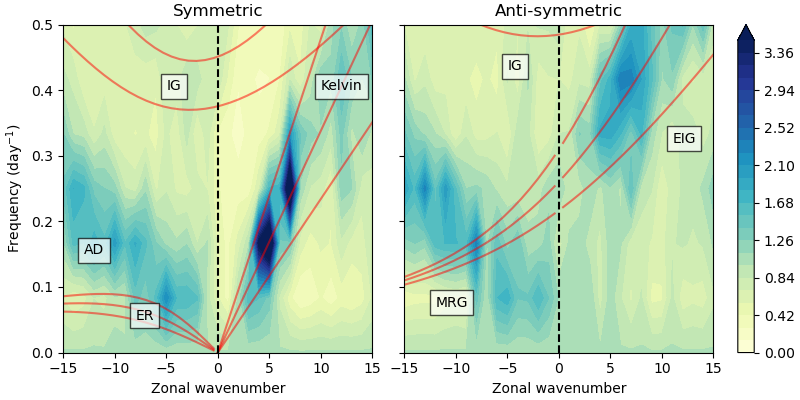

In [8]:
spec_levels = np.linspace(0, 3.5, 26)

fig, ax = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

sym_spec_im = ax[0].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')

asym_spec_im = ax[1].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')

freq, wavenum = genDispersionCurves()

labels = ['MRG', 'IG', 'EIG', 'Kelvin', 'ER', 'IG']

cols = [0.3, 0.5, 0.8]
for i in range(3):
    for j in range(3):
        ax[1].plot(wavenum[i, j], freq[i, j], color='r', alpha=0.5)
        ax[0].plot(wavenum[i+3, j], freq[i+3, j], color='r', alpha=0.5)

# Decorations
for a in ax:
    a.set_xlim(-15, 15)
    a.set_ylim(0, 0.5)
    
    a.set_xlabel('Zonal wavenumber')
    
    a.axvline(0, color='k', ls='--')

ax[0].set_ylabel('Frequency (day$^{-1}$)')
ax[1].set_yticklabels([])

ax[0].annotate('AD', (-13, 0.15), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax[0].annotate('ER', (-8, 0.05), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax[0].annotate('Kelvin', (10, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax[0].annotate('IG', (-5, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax[1].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax[1].annotate('IG', (-5, 0.43), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax[1].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax[0].set_title('Symmetric')
ax[1].set_title('Anti-symmetric')

fig.colorbar(sym_spec_im, ax=ax[-1] ,location='right')

In [9]:
def dispersion(wave_type, equivalent_depth, wavenumber=None, frequency=None, latitude=0, n=1):
    latr, perimeter, beta = get_params(latitude)
    g = 9.81
    
    if wave_type == 'Kelvin':
        if wavenumber is None:
            period = 1 / frequency
            omega = (2.0 * np.pi) / (period * 86400.0)
            k = omega / np.sqrt(g * equivalent_depth)
            wavenumber = k * perimeter / (2.0 * np.pi)
        elif frequency is None:
            k = 2.0 * np.pi * wavenumber / perimeter
            omega = np.sqrt(g * equivalent_depth) * k
            period = (2.0 * np.pi) / (omega * 86400.0)
            frequency = 1 / period
    elif wave_type == 'AD': # equivalent_depth is phase speed "c"
        if wavenumber is None:
            period = 1 / frequency
            omega = (2.0 * np.pi) / (period * 86400.0)
            k = omega / equivalent_depth
            wavenumber = -k * perimeter / (2.0 * np.pi)
        elif frequency is None:
            k = 2.0 * np.pi * wavenumber / perimeter
            omega = -equivalent_depth * k
            period = (2.0 * np.pi) / (omega * 86400.0)
            frequency = 1 / period
    elif wave_type == 'WIG':
        c = np.sqrt(g * equivalent_depth)
        
        if wavenumber is None:
            period = 1 / frequency
            omega = (2.0 * np.pi) / (period * 86400.0)
            f_disp = lambda k: np.power(omega / c, 2) - np.power(k, 2) - beta * k / omega - (2*n + 1) * beta / c
            k_guess = -np.sqrt(np.power(omega, 2) - (2*n + 1) * beta * c)/c
            k = fsolve(f_disp, k_guess)[0]
            wavenumber = k * perimeter / (2.0 * np.pi)
        elif frequency is None:
            k = 2.0 * np.pi * wavenumber / perimeter
            f_disp = lambda omega: np.power(omega / c, 2) - np.power(k, 2) - beta * k / omega - (2*n + 1) * beta / c
            omega_guess = np.sqrt(np.power(c * k, 2) + (2*n + 1) * beta * c)
            omega = fsolve(f_disp, omega_guess)[0]
            period = (2.0 * np.pi) / (omega * 86400.0)
            frequency = 1 / period
    elif wave_type in ['MRG', 'EIG']:
        c = np.sqrt(g * equivalent_depth)
        n = 0.0
        if wavenumber is None:
            period = 1 / frequency
            omega = (2.0 * np.pi) / (period * 86400.0)
            f_disp = lambda k: np.power(omega / c, 2) - np.power(k, 2) - beta * k / omega - (2*n + 1) * beta / c
            if wave_type == 'MRG':
                k_guess = -np.sqrt(np.power(omega, 2) - (2*n + 1) * beta * c)/c
            elif wave_type == 'EIG':
                k_guess = np.sqrt(np.power(omega, 2) - (2*n + 1) * beta * c)/c
            else:
                print("Must specify westward/eastward when only frequency given.")
                return np.array([np.nan, np.nan])
            k = fsolve(f_disp, k_guess)[0]
            wavenumber = k * perimeter / (2.0 * np.pi)
        elif frequency is None:
            k = 2.0 * np.pi * wavenumber / perimeter
            f_disp = lambda omega: np.power(omega / c, 2) - np.power(k, 2) - beta * k / omega - (2*n + 1) * beta / c
            if k > -np.sqrt(0.5 * beta / c):
                omega_guess = np.sqrt(np.power(c * k, 2) + (2*n + 1) * beta * c)
            else:
                omega_guess = -beta * k / (np.power(k, 2) + (2*n + 1) * beta / c)
            omega = fsolve(f_disp, omega_guess)[0]
            period = (2.0 * np.pi) / (omega * 86400.0)
            frequency = 1 / period
    elif wave_type == 'ER':
        c = np.sqrt(g * equivalent_depth)
        # k should be negative
        
        if wavenumber is None:
            period = 1 / frequency
            omega = (2.0 * np.pi) / (period * 86400.0)
            k = -0.5 * beta / omega + 0.5 * np.sqrt(np.power(beta/omega, 2) - 4 * (2*n + 1) * beta / c)
            if k > 0:
                k = -0.5 * beta / omega - 0.5 * np.sqrt(np.power(beta/omega, 2) - 4 * (2*n + 1) * beta / c)
            wavenumber = k * perimeter / (2.0 * np.pi)
        elif frequency is None:
            k = 2.0 * np.pi * wavenumber / perimeter
            omega = (-beta * k) / (np.power(k, 2)  + (2*n + 1) * beta / c)
            period = (2.0 * np.pi) / (omega * 86400.0)
            frequency = 1 / period
    else:
        print("Wave type not implemented.")
        frequency = np.nan
        wavenumber = np.nan

    return np.array([wavenumber, frequency])

In [10]:
wave_spec = {
    'Kelvin': {
         'longname': 'Kelvin Waves',
         'wavenumber': np.array([1,14],dtype='f'),
         'period': np.array([2.5,20],dtype='f'),
         'depth': np.array([8,90],dtype='f')
        },
    'AD': {
         'longname': 'Advective Disturbances',
         'wavenumber': np.array([-28, -4],dtype='f'),
         'period': np.array([5.0,20],dtype='f'),
         'depth': np.array([np.nan,np.nan],dtype='f')
        },
    'ADnak': {
         'longname': 'Advective Disturbances (Nakajima defn)',
         'wavenumber': np.array([-28, -4],dtype='f'),
         'period': np.array([2.0, np.nan],dtype='f'),
         'depth': np.array([2.5, 12],dtype='f')
        },
    'ADcwp': {
         'longname': 'Advective Disturbances (Nakajima defn)',
         'wavenumber': np.array([-28, -4],dtype='f'),
         'period': np.array([2.0, 10],dtype='f'),
         'depth': np.array([2.5, 12],dtype='f')
        },
    'MRG': {
         'longname': 'Mixed Rossby-Gravity Waves',
         'wavenumber': np.array([-10, -1],dtype='f'),
         'period': np.array([3, 10],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
    'WIG': {
         'longname': 'Westward Inertio-Gravity Waves',
         'wavenumber': np.array([-14, -1],dtype='f'),
         'period': np.array([1.8, 4.5],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
    'WIGnak': {
         'longname': 'Westward Inertio-Gravity Waves (Nakajima defn)',
         'wavenumber': np.array([-15, -1],dtype='f'),
         'period': np.array([1/0.7, np.nan],dtype='f'),
         'depth': np.array([12, 50],dtype='f')
    },
    'EIG': {
         'longname': 'Eastward Inertio-Gravity Waves',
         'wavenumber': np.array([1, 14],dtype='f'),
         'period': np.array([2, 4],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        },
    'MJO': {
         'longname': 'Madden-Julian Oscillation',
         'wavenumber': np.array([1, 5],dtype='f'),
         'period': np.array([30, 96],dtype='f'),
         'depth': np.array([np.nan, np.nan],dtype='f')
        },
    'ER': {
         'longname': 'Equatorial Rossby waves',
         'wavenumber': np.array([-10, -1],dtype='f'),
         'period': np.array([-999, 60],dtype='f'),
         'depth': np.array([8, 90],dtype='f')
        }
    }

def get_wave_boundary(waveName):
    kmin, kmax = wave_spec[waveName]['wavenumber']
    Tmin, Tmax = wave_spec[waveName]['period']
    hmin, hmax = wave_spec[waveName]['depth']
    fmin = 1./Tmin
    fmax = 1./Tmax
    
    if (waveName == 'Kelvin'):
        wave_boundary = np.array([
            [kmin, fmax],
            [dispersion('Kelvin', hmin, frequency=fmax)[0], fmax],
            [kmax, dispersion('Kelvin', hmin, wavenumber=kmax)[1]],
            [kmax, fmin],
            [dispersion('Kelvin', hmax, frequency=fmin)[0], fmin],
            [kmin, dispersion('Kelvin', hmax, wavenumber=kmin)[1]],
            [kmin, fmax]
        ]).T
    elif (waveName == 'AD'):
        wave_boundary = np.array([
            [kmin, fmin],
            [kmax, fmin],
            [kmax, fmax],
            [kmin, fmax],
            [kmin, fmin]
        ]).T
    elif (waveName == 'MJO'):
        wave_boundary = np.array([
            [kmin, fmin],
            [kmax, fmin],
            [kmax, fmax],
            [kmin, fmax],
            [kmin, fmin]
        ]).T
    elif (waveName == 'ADnak'):
        wave_boundary = np.array([
            [kmin, fmin],
            [dispersion('AD', hmax, frequency=fmin)[0], fmin],
            [kmax, dispersion('AD', hmax, wavenumber=kmax)[1]],
            [kmax, dispersion('AD', hmin, wavenumber=kmax)[1]],
            [kmin, dispersion('AD', hmin, wavenumber=kmin)[1]],
            [kmin, fmin]
        ]).T
    elif (waveName == 'ADcwp'):
        wave_boundary = np.array([
            [kmin, fmin],
            [dispersion('AD', hmax, frequency=fmin)[0], fmin],
            [dispersion('AD', hmax, frequency=fmax)[0], fmax],
            [dispersion('AD', hmin, frequency=fmax)[0], fmax],
            [kmin, dispersion('AD', hmin, wavenumber=kmin)[1]],
            [kmin, fmin]
        ]).T
    elif (waveName == 'MRG'):
        mrg_boundary1 = np.array([np.linspace(kmin, kmax, 10)[::-1], [dispersion('MRG', hmin, wavenumber=k)[1] for k in np.linspace(kmin, kmax, 10)[::-1]]])
        mrg_boundary2 = np.array([np.linspace(kmin, kmax, 10), [dispersion('MRG', hmax, wavenumber=k)[1] for k in np.linspace(kmin, kmax, 10)]])
        mrg_boundary0 = np.array([ [kmax, dispersion('MRG', hmin, wavenumber=kmax)[1]] ]).T
        wave_boundary = np.concatenate((mrg_boundary1, mrg_boundary2, mrg_boundary0), axis=1)
    elif (waveName == 'WIG'):
        wave_boundary = np.array([
            [kmin, fmin],
            [kmax, fmin],
            [kmax, fmax],
            [kmin, fmax],
            [kmin, fmin]
        ]).T
    elif (waveName == 'WIGnak'):
        klim = dispersion('WIG', hmax, frequency=fmin)[0]
        wig_boundary0 = np.array([ [kmin, fmin] ]).T
        wig_boundary1 = np.array([np.linspace(klim, kmax, 10), [dispersion('WIG', hmax, wavenumber=k)[1] for k in np.linspace(klim, kmax, 10)]])
        wig_boundary2 = np.array([np.linspace(kmin, kmax, 10)[::-1], [dispersion('WIG', hmin, wavenumber=k)[1] for k in np.linspace(kmin, kmax, 10)[::-1]]])
        wave_boundary = np.concatenate((wig_boundary0, wig_boundary1, wig_boundary2, wig_boundary0), axis=1)
    elif (waveName == 'EIG'):
        klim = dispersion('EIG', hmax, frequency=fmin)[0]
        eig_boundary0 = np.array([ [kmax, fmin] ]).T
        eig_boundary1 = np.array([np.linspace(kmin, kmax, 10)[::-1], [dispersion('EIG', hmin, wavenumber=k)[1] for k in np.linspace(kmin, kmax, 10)[::-1]]])
        eig_boundary2 = np.array([np.linspace(kmin, klim, 10), [dispersion('EIG', hmax, wavenumber=k)[1] for k in np.linspace(kmin, klim, 10)]])
        wave_boundary = np.concatenate((eig_boundary0, eig_boundary1, eig_boundary2, eig_boundary0), axis=1)
    elif (waveName == 'ER'):
        klim1 = dispersion('ER', hmin, frequency=fmax)[0]
        klim2 = dispersion('ER', hmax, frequency=fmax)[0]
        er_boundary0 = np.array([ [klim2, fmax] ]).T
        er_boundary1 = np.array([np.linspace(kmin, klim1, 10)[::-1], [dispersion('ER', hmin, wavenumber=k)[1] for k in np.linspace(kmin, klim1, 10)[::-1]]])
        er_boundary2 = np.array([np.linspace(kmin, klim2, 10), [dispersion('ER', hmax, wavenumber=k)[1] for k in np.linspace(kmin, klim2, 10)]])
        wave_boundary = np.concatenate((er_boundary0, er_boundary1, er_boundary2), axis=1)

    return wave_boundary

for waveName in wave_spec.keys():
    wave_boundary = get_wave_boundary(waveName)
    
    if waveName == 'ADcwp':
        ax[0].plot(wave_boundary[0], wave_boundary[1], color='r', linestyle='--')
    elif waveName in ['MRG', 'EIG']:
        ax[1].plot(wave_boundary[0], wave_boundary[1], color='g', linestyle='--')
    else:
        if waveName in ['AD', 'WIG']:
            ax[0].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
        else:
            ax[0].plot(wave_boundary[0], wave_boundary[1], color='g', linestyle='--')

In [11]:
def filter_data_for_ccews_cwp(fname,obsVar,obsPerDay,waveName,flipGrid=False,debug=False,tol=1e-2,**kwargs):
    
    filter_info = {
        'minLat' : 0,
        'maxLat' : 10,
        'avgLat' : True
    }
    
    for keys in kwargs:
        filter_info[keys] = kwargs[keys]
    print(filter_info)
    
    #read data    
    infile = xr.open_dataset(fname)
    lon = infile.lon
    
    # handle cdo flipping the grid
    if flipGrid:
        infile = infile.reindex(lat=infile.lat[::-1])

    obsTime = infile.Time
    nObs=len(obsTime)
    obsData = infile[obsVar].sel(lat=slice(filter_info['minLat'],filter_info['maxLat']))#.mean(dim='lat')
    
    from datetime import timedelta
    # Extend filtering by 700 days
    filtTime = np.arange(0,len(obsTime)+702)

    # Incorporate original data into array
    if (filter_info['avgLat']):
        obsData = obsData.mean('lat')
        filtData=np.zeros([len(filtTime),1,len(lon)],dtype='f')
        lat = [0]
        coords = [obsTime,lon]
        dims = ['time','lon']
        filtData[0:obsData.shape[0],0,:]=obsData  
    else:
        lat = obsData.lat
        filtData=np.zeros([len(filtTime),len(lat),len(lon)],dtype='f')
        coords = [obsTime,lat,lon]
        dims = ['time','lat','lon']
        filtData[0:obsData.shape[0],:]=obsData  
    
    wave = filtData
    
    wave_boundary = get_wave_boundary(waveName)

    #################################################
    # Filter 
    #################################################
    print("\n##############################\nFiltering %s\n"%waveName)
    if wave_spec[waveName]['wavenumber'][0] < 0:
        tol = -tol
    for lat_counter in range(0,len(lat)):
        if debug:
            wave[:,lat_counter,:], debugData =kf_filter_cwp(filtData[:,lat_counter,:],
                            wave_boundary, waveName, obsPerDay, tol, debug)
        else:
            wave[:,lat_counter,:] =kf_filter_cwp(filtData[:,lat_counter,:],
                            wave_boundary, waveName, obsPerDay, tol, debug)
        
    waveData = xr.DataArray(wave[0:len(obsTime),:].squeeze(),coords=coords,dims=dims)
        
    if debug:
        return waveData, debugData
    else:
        return waveData

In [12]:
def kf_filter_cwp(inData,wave_boundary,waveName, obsPerDay, tol, debug=False):
    timeDim = inData.shape[0]
    lonDim = inData.shape[1]
    
    # Reshape data from [time,lon] to [lon,time]
    originalData=np.zeros([lonDim,timeDim],dtype='f')
    for counterX in range(timeDim):
        test=0
        for counterY in range(lonDim-1,-1,-1):
            originalData[test,counterX]=inData[counterX,counterY]
            test+=1
    
    # Detrend the Data
    detrendData=np.zeros([lonDim,timeDim],dtype='f')
    for counterX in range(lonDim):
        detrendData[counterX,:]=signal.detrend(originalData[counterX,:])
    
    # Taper 
    taper=signal.windows.tukey(timeDim,0.05,True)
    taperData=np.zeros([lonDim,timeDim],dtype='f')
    for counterX in range(lonDim):
        taperData[counterX,:]=detrendData[counterX,:]*taper
    
    # Perform 2-D Fourier Transform
    fftData=np.fft.rfft2(taperData)
    if debug: debugData = np.ones_like(fftData)
    kDim=lonDim 
    freqDim=round(fftData.shape[1])
    
    # Wavenumbers and frequencies corresponding to fftData
    wavenum = np.fft.fftfreq(fftData.shape[0], d = 1/lonDim) # no 360. factor because wavenumber is dimensionless
    freq = np.fft.fftfreq(fftData.shape[1], d=1/obsPerDay) / 2. # adjustment because we only use half the range because it's real (?!)
    
    # Now create mask (using polygon technique)
    p = Path(wave_boundary.T)
    X, Y = np.meshgrid(wavenum, freq)
    Xf, Yf = X.flatten(), Y.flatten()
    points = np.vstack((Xf, Yf)).T
    grid = p.contains_points(points, 
                radius = tol
    )
    mask = grid.reshape(len(freq), len(wavenum)).T

    fftData = np.where(mask, fftData, 0.)
    if debug: debugData = np.where(mask, debugData, 0.)
    
    returnedData = np.fft.irfft2(fftData)
        
    # Reshape data from [lon,time] to [time,lon]
    outData=np.zeros([timeDim,lonDim],dtype='f')
    for counterX in range(returnedData.shape[1]):
        test=0
        for counterY in range(lonDim-1,-1,-1):
            outData[counterX,counterY]=returnedData[test,counterX] 
            test+=1

    if debug:
        return outData, debugData
    else:
        return outData

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering Kelvin

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering Kelvin

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering AD

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering ADnak

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering AD

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering ADcwp

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering WIG

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering WIGnak

{'minLat': 0, 'maxLat': 10, 'avgLat': True}

##############################
Filtering MRG

{'minLat': 0, 'maxLat': 10, 'avgLat': True}

##############################
Filtering MRG

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

################

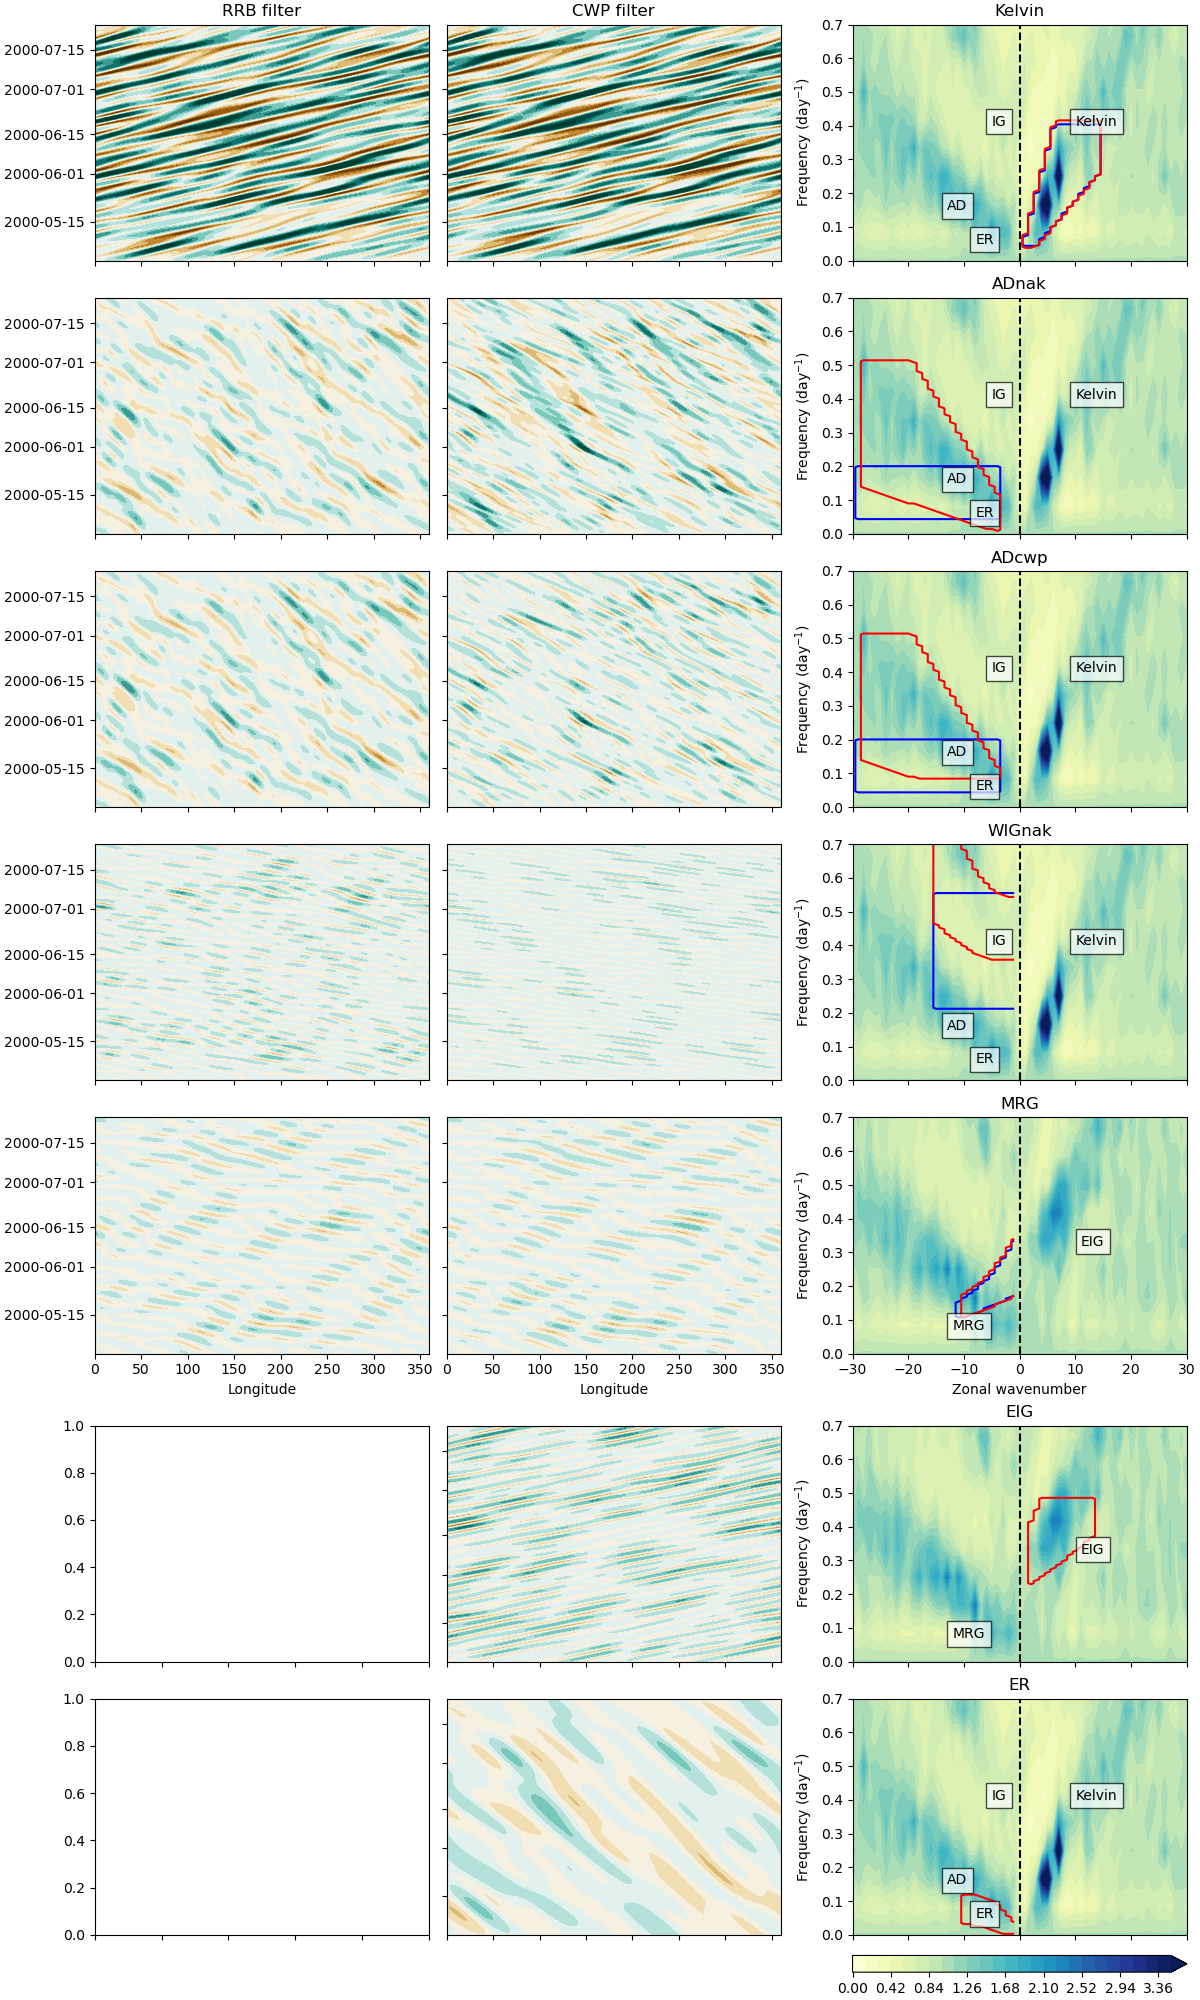

In [13]:
fig, ax = plt.subplots(7, 3, figsize=(12, 20), constrained_layout=True)

for i, (waveName, waveNameCWP) in enumerate(zip(['Kelvin', 'AD', 'AD', 'WIG', 'MRG', None, None], ['Kelvin', 'ADnak', 'ADcwp', 'WIGnak', 'MRG', 'EIG', 'ER'])):

    if waveName in ['EIG', 'MRG']:
        minLat = 0
    else:
        minLat = -10

    if waveName is not None:
        filtered, debug = filter_data_for_ccews(
            fname = data_dir+'precip_rate_n256.nc', 
            obsVar = 'precip_rate', 
            obsPerDay = 8,
            waveName = waveName,
            flipGrid = True,
            debug = True,
            minLat = minLat
        )
    
    filtered_cwp, debug_cwp = filter_data_for_ccews_cwp(
        fname = data_dir+'precip_rate_n256.nc', 
        obsVar = 'precip_rate', 
        obsPerDay = 8,
        waveName = waveNameCWP,
        flipGrid = True,
        tol = 3e-2,
        debug = True,
        minLat = minLat
    )
    
    wavenum = np.fft.fftfreq(debug.shape[0], d = 1/1024.)
    freq = np.fft.fftfreq(debug.shape[1], d=1/8.) / 2. # adjustment because we only use half the data (?!)
    
    time = filtered.time
    lons = pyg.regularlon(1024)
    levels = np.linspace(-0.3, 0.3, 13)

    if waveName is not None:
        ax[i, 0].contourf(lons, time, filtered, levels=levels, cmap='BrBG', extend='both')
        
        ax[i, 2].contour(wavenum, freq, debug.T, levels=[0.5], colors='b')
    
    ax[i, 1].contourf(lons, time, filtered_cwp, levels=levels, cmap='BrBG', extend='both')
    ax[i, 1].set_yticklabels([])

    if i != 4:
        ax[i, 0].set_xticklabels([])
        ax[i, 1].set_xticklabels([])
        ax[i, 2].set_xticklabels([])
    else:
        ax[i, 0].set_xlabel("Longitude")
        ax[i, 1].set_xlabel("Longitude")
        ax[i, 2].set_xlabel('Zonal wavenumber')

    ax[i, 2].set_title(waveNameCWP)
    ax[i, 2].contour(wavenum, freq, debug_cwp.T, levels=[0.5], colors='r')
    ax[i, 2].set_xlim(-30, 30)
    ax[i, 2].set_ylim(0, 0.7)
    
    spec_levels = np.linspace(0, 3.5, 26)


    if waveNameCWP in ['EIG', 'MRG']:
        spec_im = ax[i, 2].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
        
        ax[i, 2].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[i, 2].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
    else:
        spec_im = ax[i, 2].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
        
        ax[i, 2].annotate('AD', (-13, 0.15), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[i, 2].annotate('ER', (-8, 0.05), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[i, 2].annotate('Kelvin', (10, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[i, 2].annotate('IG', (-5, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

    ax[i, 2].axvline(0, color='k', ls='--')
    ax[i, 2].set_ylabel('Frequency (day$^{-1}$)')

ax[0, 0].set_title("RRB filter")
ax[0, 1].set_title("CWP filter")
fig.colorbar(sym_spec_im, ax=ax[i, -1], location='bottom')

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering Kelvin

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering ADcwp

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering WIGnak

{'minLat': -10, 'maxLat': 10, 'avgLat': True}

##############################
Filtering ER



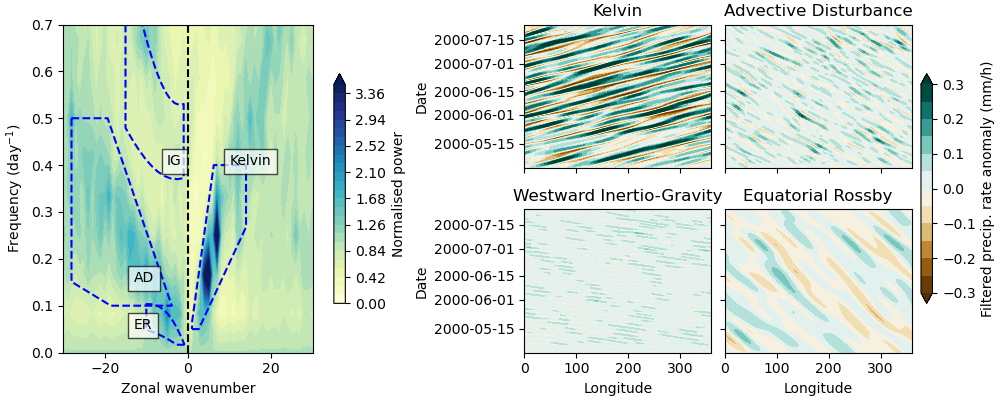

In [16]:
fig = plt.figure(figsize=(10, 4), constrained_layout=True)
ax = fig.subplot_mosaic(
    [
        ["A", "B", "C"],
        ["A", "D", "E"]
    ],
    width_ratios=[0.4, 0.3, 0.3]
)

pos = ["B", "C", "D", "E"]

#for i, (waveName, title) in enumerate(zip(['Kelvin', 'ADcwp', 'WIGnak', 'MRG', 'EIG', 'ER'], ['Kelvin', 'Adv. Dist.', 'W Inertio-Gravity', 'Mixed Rossby-Gravity', 'E Inerio-Gravity', 'Equatorial Rossby'])):
for i, (waveName, title) in enumerate(zip(['Kelvin', 'ADcwp', 'WIGnak', 'ER'], ['Kelvin', 'Advective Disturbance', 'Westward Inertio-Gravity', 'Equatorial Rossby'])):

    filtered, debug = filter_data_for_ccews_cwp(
        fname = data_dir+'precip_rate_n256.nc', 
        obsVar = 'precip_rate', 
        obsPerDay = 8,
        waveName = waveName,
        flipGrid = True,
        tol = 3e-2,
        debug = True,
        minLat = -10
    )
    
    wavenum = np.fft.fftfreq(debug.shape[0], d = 1/1024.)
    freq = np.fft.fftfreq(debug.shape[1], d=1/8.) / 2. # adjustment because we only use half the data (?!)
    
    time = filtered.time
    lons = pyg.regularlon(1024)
    levels = np.linspace(-0.3, 0.3, 13)

    filter_im = ax[pos[i]].contourf(lons, time, filtered, levels=levels, cmap='BrBG', extend='both')
    
    #ax["A"].contour(wavenum, freq, debug.T, levels=[0.5], colors='b')

    ax[pos[i]].set_title(title)
    
    wave_boundary = get_wave_boundary(waveName)
    
    if waveName == 'ADcwp':
        ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
    elif waveName in ['MRG', 'EIG']:
        ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
    else:
        if waveName in ['AD', 'WIG']:
            ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
        else:
            ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')

spec_levels = np.linspace(0, 3.5, 26)
#spec_im = ax["A"].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
spec_im = ax["A"].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
        
ax["A"].set_xlabel('Zonal wavenumber')
ax["A"].set_xlim(-30, 30)
ax["A"].set_ylim(0, 0.7)

#ax["A"].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
#ax["A"].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax["A"].annotate('AD', (-13, 0.15), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax["A"].annotate('ER', (-13, 0.05), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax["A"].annotate('Kelvin', (10, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax["A"].annotate('IG', (-5, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax["A"].axvline(0, color='k', ls='--')
ax["A"].set_ylabel('Frequency (day$^{-1}$)')

ax["C"].set_yticklabels([])
ax["E"].set_yticklabels([])
ax["B"].set_ylabel("Date")
ax["D"].set_ylabel("Date")

ax["B"].set_xticklabels([])
ax["C"].set_xticklabels([])

ax["D"].set_xlabel("Longitude")
ax["E"].set_xlabel("Longitude")

fig.colorbar(sym_spec_im, ax=ax["A"], location='right', shrink=0.7, label="Normalised power")
fig.colorbar(filter_im, ax=[ax["C"], ax["E"]], location='right', shrink=0.7, label="Filtered precip. rate anomaly (mm/h)")

save_fig(fig, '/home/cwp29/tmp/mpas/wave_filter_sym.png', dpi=300)

{'minLat': 0, 'maxLat': 10, 'avgLat': True}

##############################
Filtering MRG

{'minLat': 0, 'maxLat': 10, 'avgLat': True}

##############################
Filtering EIG



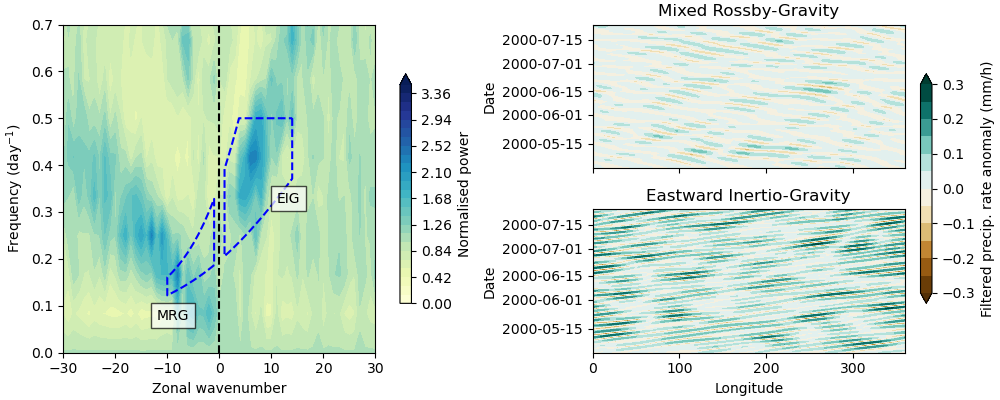

In [17]:
fig = plt.figure(figsize=(10, 4), constrained_layout=True)
ax = fig.subplot_mosaic(
    [
        ["A", "B"],
        ["A", "C"]
    ],
    width_ratios=[0.5, 0.5]
)

pos = ["B", "C"]

# Need to add antisymmetric component of advective disturbances

for i, (waveName, title) in enumerate(zip(['MRG', 'EIG'], ['Mixed Rossby-Gravity', 'Eastward Inertio-Gravity'])):

    filtered, debug = filter_data_for_ccews_cwp(
        fname = data_dir+'precip_rate_n256.nc', 
        obsVar = 'precip_rate', 
        obsPerDay = 8,
        waveName = waveName,
        flipGrid = True,
        tol = 3e-2,
        debug = True,
        minLat = 0
    )
    
    wavenum = np.fft.fftfreq(debug.shape[0], d = 1/1024.)
    freq = np.fft.fftfreq(debug.shape[1], d=1/8.) / 2. # adjustment because we only use half the data (?!)
    
    time = filtered.time
    lons = pyg.regularlon(1024)
    levels = np.linspace(-0.3, 0.3, 13)

    filter_im = ax[pos[i]].contourf(lons, time, filtered, levels=levels, cmap='BrBG', extend='both')
    
    #ax["A"].contour(wavenum, freq, debug.T, levels=[0.5], colors='b')

    ax[pos[i]].set_title(title)
    
    wave_boundary = get_wave_boundary(waveName)
    
    if waveName == 'ADcwp':
        ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
    elif waveName in ['MRG', 'EIG']:
        ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
    else:
        if waveName in ['AD', 'WIG']:
            ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')
        else:
            ax["A"].plot(wave_boundary[0], wave_boundary[1], color='b', linestyle='--')

spec_levels = np.linspace(0, 3.5, 26)
spec_im = ax["A"].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
        
ax["A"].set_xlabel('Zonal wavenumber')
ax["A"].set_xlim(-30, 30)
ax["A"].set_ylim(0, 0.7)

ax["A"].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
ax["A"].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax["A"].axvline(0, color='k', ls='--')
ax["A"].set_ylabel('Frequency (day$^{-1}$)')

ax["B"].set_xticklabels([])

ax["B"].set_ylabel("Date")
ax["C"].set_ylabel("Date")

ax["C"].set_xlabel("Longitude")

fig.colorbar(sym_spec_im, ax=ax["A"], location='right', shrink=0.7, label="Normalised power")
fig.colorbar(filter_im, ax=[ax["B"], ax["C"]], location='right', shrink=0.7, label="Filtered precip. rate anomaly (mm/h)")

save_fig(fig, '/home/cwp29/tmp/mpas/wave_filter_asym.png', dpi=300)